# Embeddings as Features

An **embedding** is a dense vector that represents an object (a text, an image, a product, a user) so that similar objects have similar vectors. Pretrained embedding models turn unstructured data into features that a simple classifier can use, often with very little labelled data.

**After this lesson you can:**

1. Turn texts into features with TF-IDF and with a pretrained embedding model.
2. Compare them by accuracy, dimensionality and the amount of labelled data needed.
3. Combine embeddings with tabular features.
4. Explain the costs and risks of embedding features.

**Data:** 20 Newsgroups (public text classification benchmark, via scikit-learn), four topics. Embeddings: `nomic-embed-text` served by Ollama (free, local).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

import json
import urllib.request

from sklearn.datasets import fetch_20newsgroups
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline

TOPICS = ["rec.autos", "sci.med", "comp.graphics", "talk.politics.mideast"]
news = fetch_20newsgroups(subset="all", categories=TOPICS, remove=("headers", "footers", "quotes"), random_state=RNG)
texts = pd.Series(news.data).str.slice(0, 800)                         # first 800 characters keep embedding fast
labels = pd.Series(np.array(news.target_names)[news.target])
keep = texts.str.split().str.len() >= 20                              # drop near-empty posts
texts, labels = texts[keep], labels[keep]
sample = labels.groupby(labels).sample(300, random_state=RNG).index   # 300 posts per topic
texts, labels = texts.loc[sample].reset_index(drop=True), labels.loc[sample].reset_index(drop=True)
print(f"{len(texts)} posts | topics: {labels.value_counts().to_dict()}")

1200 posts | topics: {'comp.graphics': 300, 'rec.autos': 300, 'sci.med': 300, 'talk.politics.mideast': 300}


## 1. Two Representations

| | TF-IDF | Pretrained embedding |
| :--- | :--- | :--- |
| how | counts of words, weighted by rarity | a neural network trained on huge text collections |
| size | sparse, ~10⁴–10⁵ columns | dense, here 768 columns |
| knows synonyms? | no ("car" ≠ "automobile") | yes, roughly |
| cost | very cheap | a model call per text |

In [2]:
OLLAMA = "http://localhost:11434"

def embed(batch: list[str]) -> np.ndarray:
    req = urllib.request.Request(f"{OLLAMA}/api/embed", data=json.dumps({"model": "nomic-embed-text", "input": batch}).encode(),
                                 headers={"Content-Type": "application/json"})
    with urllib.request.urlopen(req, timeout=600) as r:
        return np.array(json.load(r)["embeddings"], dtype=np.float32)

t = time.perf_counter()
E = np.vstack([embed(texts.iloc[i:i + 64].tolist()) for i in range(0, len(texts), 64)])
emb_seconds = time.perf_counter() - t
tfidf = TfidfVectorizer(min_df=3, stop_words="english", sublinear_tf=True)
T = tfidf.fit_transform(texts)
print(f"embeddings: {E.shape} in {emb_seconds:.0f} s | TF-IDF: {T.shape}, {T.nnz / T.shape[0]:.0f} non-zero values per text")

embeddings: (1200, 768) in 331 s | TF-IDF: (1200, 3538), 28 non-zero values per text


## 2. Accuracy and Labelled-Data Efficiency

The same logistic regression is trained on each representation, with training sets from 20 to about 700 labelled posts, and evaluated on the same held-out test set. (The TF-IDF vocabulary was fitted on all texts without labels, which is acceptable for a learning-curve comparison.)

features        TF-IDF  embeddings
labelled posts                    
20               0.615       0.898
40               0.679       0.935
100              0.790       0.938
200              0.829       0.938
400              0.896       0.946
720              0.904       0.942


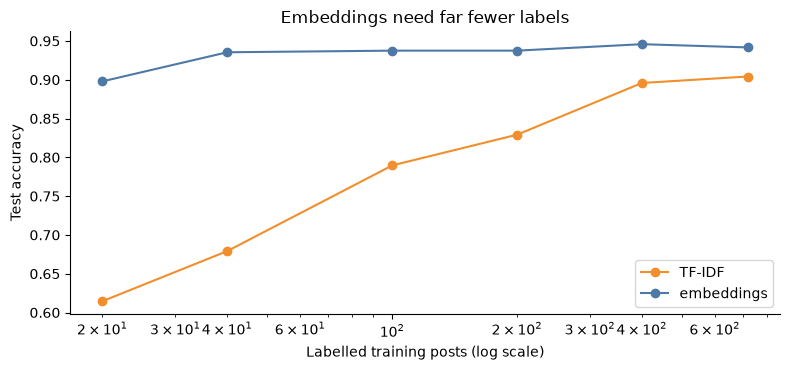

In [3]:
idx_tr, idx_te = train_test_split(np.arange(len(texts)), test_size=0.4, stratify=labels, random_state=RNG)
rows = []
for n in [20, 40, 100, 200, 400, 720]:
    sub = pd.Series(idx_tr).groupby(labels.iloc[idx_tr].values).head(n // 4).to_numpy()
    for name, X in [("TF-IDF", T), ("embeddings", E)]:
        clf = LogisticRegression(max_iter=3000, C=10 if name == "TF-IDF" else 1).fit(X[sub], labels.iloc[sub])
        rows.append({"labelled posts": len(sub), "features": name, "accuracy": accuracy_score(labels.iloc[idx_te], clf.predict(X[idx_te]))})
curve = pd.DataFrame(rows).pivot(index="labelled posts", columns="features", values="accuracy")
print(curve.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
for col, c in [("TF-IDF", "#F28E2B"), ("embeddings", "#4E79A7")]:
    ax.plot(curve.index, curve[col], marker="o", color=c, label=col)
ax.set(xscale="log", xlabel="Labelled training posts (log scale)", ylabel="Test accuracy", title="Embeddings need far fewer labels")
ax.legend()
plt.tight_layout()
plt.show()

## 3. What the Embedding Space Looks Like

A 2-D PCA projection of the 768-dimensional embeddings already separates the topics, although the model never saw the labels.

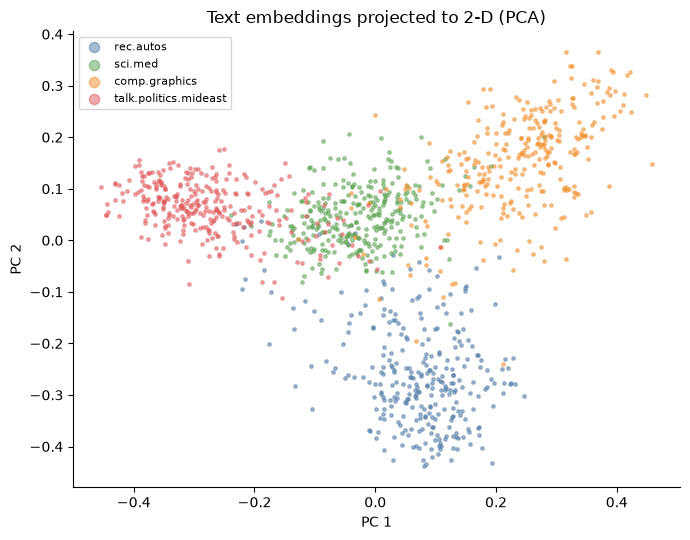

In [4]:
P = PCA(2, random_state=RNG).fit_transform(E)
fig, ax = plt.subplots(figsize=(7, 5.5))
for topic, c in zip(TOPICS, ["#4E79A7", "#59A14F", "#F28E2B", "#E15759"]):
    m = (labels == topic).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=6, alpha=0.5, color=c, label=topic)
ax.set(title="Text embeddings projected to 2-D (PCA)", xlabel="PC 1", ylabel="PC 2")
ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

## 4. Embeddings plus Tabular Features

In real tabular problems, a text column (a product description, a support ticket) is one input among many. Concatenate the embedding (or a PCA-reduced version of it) with the other features. Here, the "tabular" feature is the length of the post, combined with the embedding. In this case the length adds nothing, because the embedding already reflects it; in real problems, tabular features (price, customer history) often carry information that the text does not, and the combination wins.

In [5]:
length = np.log1p(texts.str.len().to_numpy())[:, None]
E50 = PCA(50, random_state=RNG).fit(E[idx_tr]).transform(E)
combos = {"post length only": length, "embedding (PCA 50)": E50, "embedding (PCA 50) + length": np.hstack([E50, length])}
for name, X in combos.items():
    clf = make_pipeline(LogisticRegression(max_iter=3000)).fit(X[idx_tr], labels.iloc[idx_tr])
    print(f"{name:<30} accuracy {accuracy_score(labels.iloc[idx_te], clf.predict(X[idx_te])):.3f}  ({X.shape[1]} features)")

post length only               accuracy 0.321  (1 features)
embedding (PCA 50)             accuracy 0.946  (50 features)
embedding (PCA 50) + length    accuracy 0.942  (51 features)


## 5. Costs and Risks

| Topic | Note |
| :--- | :--- |
| compute | one model call per text; cache embeddings (store them, M07 L14) |
| versioning | a new embedding model gives incompatible vectors: re-embed everything, store the model name with the vectors |
| leakage | embedding models are pretrained on public data; benchmark texts may be in their training data |
| privacy | sending texts to an external API shares them; local models (Ollama) avoid it |
| explainability | 768 dimensions have no individual meaning |

*Insight: Pretrained embeddings turn unstructured inputs into strong, compact features and need far fewer labels than sparse word counts. Treat them as a versioned, cached feature: store the model name with every vector and re-embed when you change models.*

In [6]:
urllib.request.urlopen(urllib.request.Request(f"{OLLAMA}/api/generate", data=json.dumps({"model": "nomic-embed-text", "keep_alive": 0}).encode(),
                                              headers={"Content-Type": "application/json"}), timeout=30).read()
print("embedding model unloaded from memory")

embedding model unloaded from memory


## Real-World Use Case or Analogy

An embedding is like **summarising each book with a set of coordinates on a map of topics**: you do not need to read the book again to know which shelf it belongs on, and a librarian can sort new books with only a few examples per shelf.

Support teams route tickets with embeddings + small classifiers, e-commerce platforms use product-description embeddings in ranking models, and the same vectors power semantic search and RAG (M28).